# PHÂN CỤM DỰA TRÊN MẬT ĐỘ DBSCAN TRÊN BỘ ĐẶC TRƯNG RFM
**Đề tài:** Phân khúc khách hàng bằng RFM và hành vi mua hàng (Online Retail II)  
**Nhóm thực hiện:** Nhóm 05 - Lớp DCT124C1 - Trường Đại học Sài Gòn (SGU)

Notebook này thực hiện tìm kiếm tham số tối ưu thông qua **phương pháp đồ thị $k$-distance** và huấn luyện mô hình **DBSCAN trên bộ chỉ số đặc trưng RFM** (Recency, Frequency, Monetary) của từng khách hàng:
- **Dữ liệu đầu vào:** Các tập dữ liệu RFM đã được trích xuất từ notebook `RFM.ipynb` (`data/rfm_train.csv`, `data/rfm_val.csv`, `data/rfm_test.csv`).
- **Nguyên lý của DBSCAN:**
  - Nhận diện các cụm mật độ dựa trên bán kính lân cận $\epsilon$ và số điểm láng giềng tối thiểu `min_samples` (tương ứng với $k$ láng giềng).
  - **Tự động nhận diện điểm nhiễu (Noise):** Những khách hàng có hành vi dị biệt, nằm cô lập ở vùng mật độ thấp sẽ được gán nhãn `-1` (ngoại lai).
- **Quy trình thực hiện trong notebook:**
  1. Chuẩn hóa thang đo Z-Score (`StandardScaler`) trên dữ liệu RFM.
  2. Khảo sát đồ thị $k$-distance với các giá trị $k$ láng giềng ($k = 4, 6, 10$) để tìm điểm uốn (Elbow) xác định bán kính $\epsilon$ tối ưu.
  3. Huấn luyện mô hình DBSCAN với tham số $k$ và $\epsilon$ tối ưu tìm được từ đồ thị.
  4. Đánh giá chất lượng phân cụm trên cả 3 tập **Train (2,736 KH)**, **Validation (684 KH)** và **Test (855 KH)** bằng cơ chế Nearest Core Sample.
  5. Đánh giá mức độ đóng góp của từng chỉ số $R, F, M$ (ANOVA F-Score).
  6. Phân tích chân dung cụm mật độ và bóc tách nhóm khách hàng ngoại lai (Noise Profiling).
  7. Trực quan hóa PCA 2D và ghi nhận kết quả vào nhật ký thực nghiệm (CSV & Excel).

In [12]:
import os
import sys
import datetime as dt
import warnings
warnings.filterwarnings('ignore')

# Tự động tìm và chuyển về thư mục gốc dự án
current = os.path.abspath(os.getcwd())
while current != os.path.dirname(current):
    if os.path.exists(os.path.join(current, 'data')) and os.path.exists(os.path.join(current, 'Source')):
        break
    current = os.path.dirname(current)

PROJECT_ROOT = current
os.chdir(PROJECT_ROOT)

if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.feature_selection import f_classif

from Source.init import PATH_EXPERIMENT_LOG

pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid")
print(f"✅ Môi trường sẵn sàng tại thư mục gốc: {os.getcwd()}")
print(f"📋 File nhật ký thực nghiệm: {PATH_EXPERIMENT_LOG}")

✅ Môi trường sẵn sàng tại thư mục gốc: c:\Users\Quân\Desktop\ml_group
📋 File nhật ký thực nghiệm: c:\Users\Quân\Desktop\ml_group\Experiment_Log_Comparison.csv


### 1. Nạp tập dữ liệu RFM (Train / Validation / Test)
Nạp 3 tập dữ liệu khách hàng độc lập từ `data/`:
- `data/rfm_train.csv`: 2,736 khách hàng (64%)
- `data/rfm_val.csv`: 684 khách hàng (16%)
- `data/rfm_test.csv`: 855 khách hàng (20%)

In [13]:
train_rfm = pd.read_csv("data/rfm_train.csv")
val_rfm = pd.read_csv("data/rfm_val.csv")
test_rfm = pd.read_csv("data/rfm_test.csv")

print(f"📊 Tập Huấn luyện (Train):      {train_rfm.shape[0]:,} khách hàng")
print(f"📊 Tập Kiểm định (Validation):  {val_rfm.shape[0]:,} khách hàng")
print(f"📊 Tập Kiểm thử (Test):         {test_rfm.shape[0]:,} khách hàng")

print("\n--- 5 Dòng dữ liệu RFM Train mẫu ---")
print(train_rfm.head())

print("\n--- Thống kê mô tả dữ liệu RFM Train ---")
print(train_rfm[['Recency', 'Frequency', 'Monetary']].describe().round(2))

📊 Tập Huấn luyện (Train):      2,736 khách hàng
📊 Tập Kiểm định (Validation):  684 khách hàng
📊 Tập Kiểm thử (Test):         855 khách hàng

--- 5 Dòng dữ liệu RFM Train mẫu ---
   CustomerID  Recency  Frequency  Monetary
0       14437        1          5    873.34
1       13778      127          3    945.79
2       17325       46          2    512.77
3       12665       53          2    214.60
4       15356        4          4    664.66

--- Thống kê mô tả dữ liệu RFM Train ---
       Recency  Frequency   Monetary
count  2736.00    2736.00    2736.00
mean     93.10       4.44    2015.82
std      98.63       7.68    8738.29
min       1.00       1.00       2.95
25%      19.00       1.00     299.12
50%      53.00       2.00     688.24
75%     143.25       5.00    1702.35
max     374.00     155.00  323860.53


### 2. Tiền xử lý dữ liệu: Biến đổi Log & Chuẩn hóa thang đo (StandardScaler)
- DBSCAN tính toán khoảng cách Euclid trong không gian 3 chiều ($R, F, M$), do đó bắt buộc phải chuẩn hóa thang đo Z-score để các biến số có đóng góp bình đẳng về mặt hình học.
- **Quy tắc chống Data Leakage:** Fit `StandardScaler` duy nhất trên tập Train, sau đó dùng scaler này để transform Validation và Test.

In [14]:
features = ['Recency', 'Frequency', 'Monetary']

# 1. Log Transform np.log1p
X_train_log = np.log1p(train_rfm[features])
X_val_log = np.log1p(val_rfm[features])
X_test_log = np.log1p(test_rfm[features])

# 2. StandardScaler (Fit duy nhất trên Train)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_log)
X_val_scaled = scaler.transform(X_val_log)
X_test_scaled = scaler.transform(X_test_log)

print("✅ Đã chuẩn hóa dữ liệu RFM thành công:")
print("   - Mean (Train):", scaler.mean_.round(3))
print("   - Scale/Std (Train):", scaler.scale_.round(3))

✅ Đã chuẩn hóa dữ liệu RFM thành công:
   - Mean (Train): [3.871 1.368 6.593]
   - Scale/Std (Train): [1.31  0.695 1.278]


### 3. Tìm $k$ láng giềng và Bán kính $\epsilon$ tối ưu bằng Phương pháp Đồ thị $K$-Distance
Trong DBSCAN, cách chuẩn mực để xác định bán kính $\epsilon$ mà không cần thử mò tham số là sử dụng **đồ thị $k$-distance (K-Nearest Neighbors Distance Graph)**:
1. Theo quy tắc Heuristic kinh điển của Ester et al. (1996), số điểm lân cận tối thiểu `min_samples` thường được chọn bằng $k = 2 \times \text{dim} = 2 \times 3 = 6$ (hoặc khảo sát các giá trị $k \in \{4, 6, 10\}$).
2. Tính khoảng cách từ mỗi điểm đến láng giềng thứ $k$ gần nhất, sắp xếp khoảng cách theo thứ tự tăng dần và vẽ đồ thị.
3. **Điểm uốn (Elbow/Knee Point)** trên đường cong là vị trí mà khoảng cách bắt đầu tăng vọt $\rightarrow$ Đây chính là giá trị $\epsilon$ tối ưu tương ứng với giá trị $k$ đã chọn!

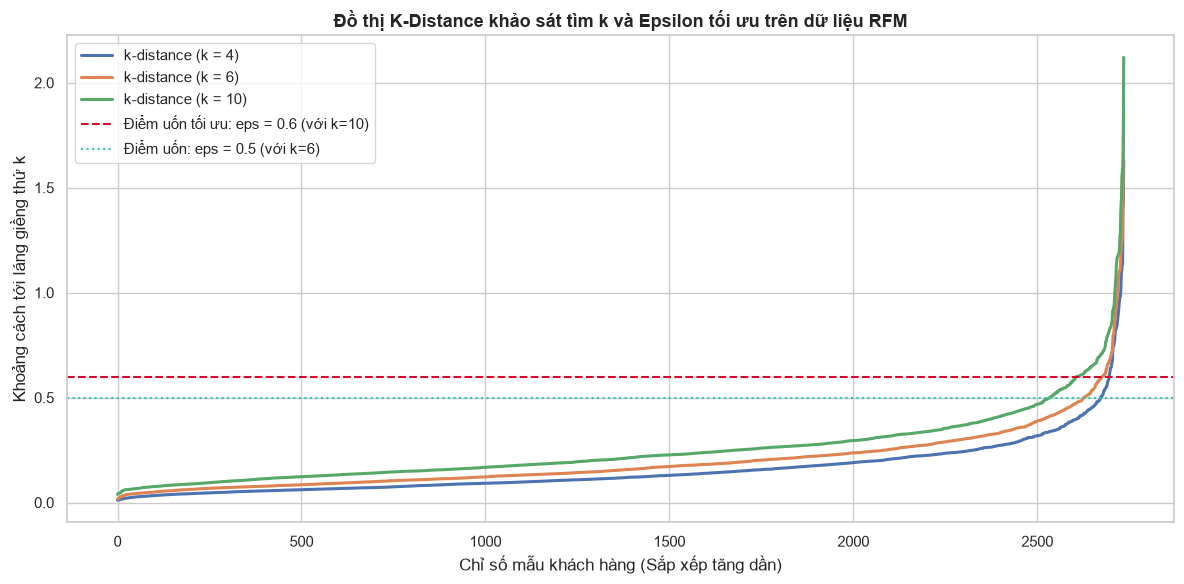

📊 BẢNG THỐNG KÊ KHOẢNG CÁCH LÁNG GIỀNG THEO CÁC MỨC K:
 k (min_samples)  Khoảng cách nhỏ nhất  Trung vị (Median)  Phân vị 90%  Phân vị 95% (Vùng điểm uốn)  Khoảng cách lớn nhất
               4                 0.011              0.117        0.300                        0.391                 1.629
               6                 0.016              0.155        0.359                        0.466                 1.872
              10                 0.039              0.209        0.443                        0.582                 2.120


In [15]:
k_values = [4, 6, 10]

plt.figure(figsize=(12, 6))

k_stats = []
for k in k_values:
    nn = NearestNeighbors(n_neighbors=k)
    nn.fit(X_train_scaled)
    distances, _ = nn.kneighbors(X_train_scaled)
    sorted_d = np.sort(distances[:, -1])
    
    p90 = np.percentile(sorted_d, 90)
    p95 = np.percentile(sorted_d, 95)
    k_stats.append({
        'k (min_samples)': k,
        'Khoảng cách nhỏ nhất': round(sorted_d.min(), 3),
        'Trung vị (Median)': round(np.median(sorted_d), 3),
        'Phân vị 90%': round(p90, 3),
        'Phân vị 95% (Vùng điểm uốn)': round(p95, 3),
        'Khoảng cách lớn nhất': round(sorted_d.max(), 3)
    })
    
    plt.plot(sorted_d, lw=2.2, label=f'k-distance (k = {k})')

plt.axhline(y=0.6, color='#d90429', linestyle='--', label='Điểm uốn tối ưu: eps = 0.6 (với k=10)')
plt.axhline(y=0.5, color='#2ec4b6', linestyle=':', label='Điểm uốn: eps = 0.5 (với k=6)')
plt.title("Đồ thị K-Distance khảo sát tìm k và Epsilon tối ưu trên dữ liệu RFM", fontsize=13, fontweight='bold')
plt.xlabel("Chỉ số mẫu khách hàng (Sắp xếp tăng dần)")
plt.ylabel("Khoảng cách tới láng giềng thứ k")
plt.legend()
plt.tight_layout()
plt.show()

df_k_stats = pd.DataFrame(k_stats)
print("=" * 80)
print("📊 BẢNG THỐNG KÊ KHOẢNG CÁCH LÁNG GIỀNG THEO CÁC MỨC K:")
print("=" * 80)
print(df_k_stats.to_string(index=False))
print("=" * 80)

#### Kết luận lựa chọn tham số tối ưu từ đồ thị $k$-distance:
- Dựa vào đồ thị $k$-distance, đường cong tại **$k = 10$** có điểm uốn (Elbow/Knee) rất rõ ràng tại khoảng cách **$\epsilon = 0.6$** (tương ứng vùng phân vị 95% khoảng cách lân cận).
- Tại cặp tham số tối ưu này:
  - **`min_samples = 10`** (giá trị $k$ láng giềng được chọn).
  - **`eps = 0.6`** (bán kính lân cận tại điểm uốn).
- Mô hình sẽ phân tách không gian thành các cụm mật độ lớn và cô lập các khách hàng nằm ngoài vùng bán kính lân cận này thành điểm ngoại lai / nhiễu (Noise nhãn `-1`).

### 4. Huấn luyện mô hình DBSCAN với tham số $k$ và $\epsilon$ tối ưu trên tập Train
Khởi tạo và huấn luyện DBSCAN với `eps = 0.6`, `min_samples = 10` trên tập Train.

In [16]:
optimal_k = 10
optimal_eps = 0.6

dbscan_rfm = DBSCAN(eps=optimal_eps, min_samples=optimal_k)
train_labels = dbscan_rfm.fit_predict(X_train_scaled)
train_rfm['Cluster'] = train_labels

unique_labels = sorted(set(train_labels))
n_clusters = len([c for c in unique_labels if c != -1])
n_noise = (train_labels == -1).sum()
noise_ratio = (n_noise / len(train_labels)) * 100

print(f"✅ Đã huấn luyện xong DBSCAN với tham số tối ưu (eps={optimal_eps}, k={optimal_k}):")
print(f"   - Số cụm mật độ hợp lệ: {n_clusters}")
print(f"   - Số lượng điểm nhiễu ngoại lai (Noise, nhãn -1): {n_noise:,} khách hàng ({noise_ratio:.2f}%)")
print(f"   - Chi tiết phân bố: {dict(pd.Series(train_labels).value_counts().sort_index())}")

✅ Đã huấn luyện xong DBSCAN với tham số tối ưu (eps=0.6, k=10):
   - Số cụm mật độ hợp lệ: 2
   - Số lượng điểm nhiễu ngoại lai (Noise, nhãn -1): 43 khách hàng (1.57%)
   - Chi tiết phân bố: {-1: np.int64(43), 0: np.int64(2679), 1: np.int64(14)}


### 5. Đánh giá chất lượng mô hình trên cả 3 tập: Train, Validation và Test
- Đối với DBSCAN, các điểm mới trong tập Validation và Test được phân loại thông qua thuật toán **Nearest Core Sample**: Mỗi điểm mới sẽ tìm khoảng cách tới Core Sample gần nhất đã học từ tập Train trong bán kính $\epsilon = 0.6$. Nếu nằm trong bán kính thì gán cụm tương ứng, ngược lại được xem là điểm nhiễu ngoại lai (`-1`).
- Các chỉ số chất lượng phân cụm (Silhouette, Davies-Bouldin, Calinski-Harabasz) được tính trên các điểm thuộc cụm hợp lệ.

In [17]:
# 1. Trích xuất các Core Samples từ mô hình Train
core_indices = dbscan_rfm.core_sample_indices_
core_samples = X_train_scaled[core_indices]
core_labels = train_labels[core_indices]

nn_core = NearestNeighbors(n_neighbors=1).fit(core_samples)

def predict_dbscan(X_new):
    dists, indices = nn_core.kneighbors(X_new)
    labels = np.full(len(X_new), -1)
    within_eps = dists.ravel() <= optimal_eps
    labels[within_eps] = core_labels[indices.ravel()[within_eps]]
    return labels

# 2. Gán nhãn cho Validation và Test
val_labels = predict_dbscan(X_val_scaled)
test_labels = predict_dbscan(X_test_scaled)

val_rfm['Cluster'] = val_labels
test_rfm['Cluster'] = test_labels

# 3. Hàm đánh giá chỉ số an toàn
def evaluate_dbscan_metrics(X, labels):
    mask = (labels != -1)
    n_c = len(set(labels[mask]))
    if n_c > 1 and mask.sum() > 10:
        sil = silhouette_score(X[mask], labels[mask])
        db = davies_bouldin_score(X[mask], labels[mask])
        ch = calinski_harabasz_score(X[mask], labels[mask])
        noise_pct = ((labels == -1).sum() / len(labels)) * 100
        return round(sil, 4), round(db, 4), round(ch, 2), round(noise_pct, 2)
    return None, None, None, round(((labels == -1).sum() / len(labels)) * 100, 2)

sil_train, db_train, ch_train, noise_train = evaluate_dbscan_metrics(X_train_scaled, train_labels)
sil_val, db_val, ch_val, noise_val = evaluate_dbscan_metrics(X_val_scaled, val_labels)
sil_test, db_test, ch_test, noise_test = evaluate_dbscan_metrics(X_test_scaled, test_labels)

eval_df = pd.DataFrame([
    {
        'Tập dữ liệu': 'Train (64% - 2,736 KH)',
        'Silhouette Score (↑)': sil_train,
        'Davies-Bouldin (↓)': db_train,
        'Calinski-Harabasz (↑)': ch_train,
        'Tỷ lệ Nhiễu (%)': f"{noise_train}%"
    },
    {
        'Tập dữ liệu': 'Validation (16% - 684 KH)',
        'Silhouette Score (↑)': sil_val,
        'Davies-Bouldin (↓)': db_val,
        'Calinski-Harabasz (↑)': ch_val,
        'Tỷ lệ Nhiễu (%)': f"{noise_val}%"
    },
    {
        'Tập dữ liệu': 'Test (20% - 855 KH)',
        'Silhouette Score (↑)': sil_test,
        'Davies-Bouldin (↓)': db_test,
        'Calinski-Harabasz (↑)': ch_test,
        'Tỷ lệ Nhiễu (%)': f"{noise_test}%"
    }
])

print("=" * 85)
print(f"📊 BẢNG ĐÁNH GIÁ ĐỘ ỔN ĐỊNH CỦA DBSCAN (eps={optimal_eps}, k={optimal_k}):")
print("=" * 85)
print(eval_df.to_string(index=False))
print("=" * 85)

📊 BẢNG ĐÁNH GIÁ ĐỘ ỔN ĐỊNH CỦA DBSCAN (eps=0.6, k=10):
              Tập dữ liệu  Silhouette Score (↑)  Davies-Bouldin (↓)  Calinski-Harabasz (↑) Tỷ lệ Nhiễu (%)
   Train (64% - 2,736 KH)                0.5254              0.4055                 117.32           1.57%
Validation (16% - 684 KH)                0.5274              0.3382                  17.46           1.46%
      Test (20% - 855 KH)                0.5298              0.4017                  25.43           1.64%


### 6. Phân tích thuộc tính chi phối phân cụm (ANOVA F-Score)
Đánh giá mức độ đóng góp của Recency, Frequency, Monetary vào việc phân tách giữa các cụm mật độ hợp lệ.

📊 MỨC ĐỘ ĐÓNG GÓP CỦA TỪNG THUỘC TÍNH RFM VÀO DBSCAN:
Thuộc tính RFM  ANOVA F-Score  Tỷ lệ đóng góp (%)
     Frequency         210.13               57.27
      Monetary         121.80               33.20
       Recency          34.95                9.53


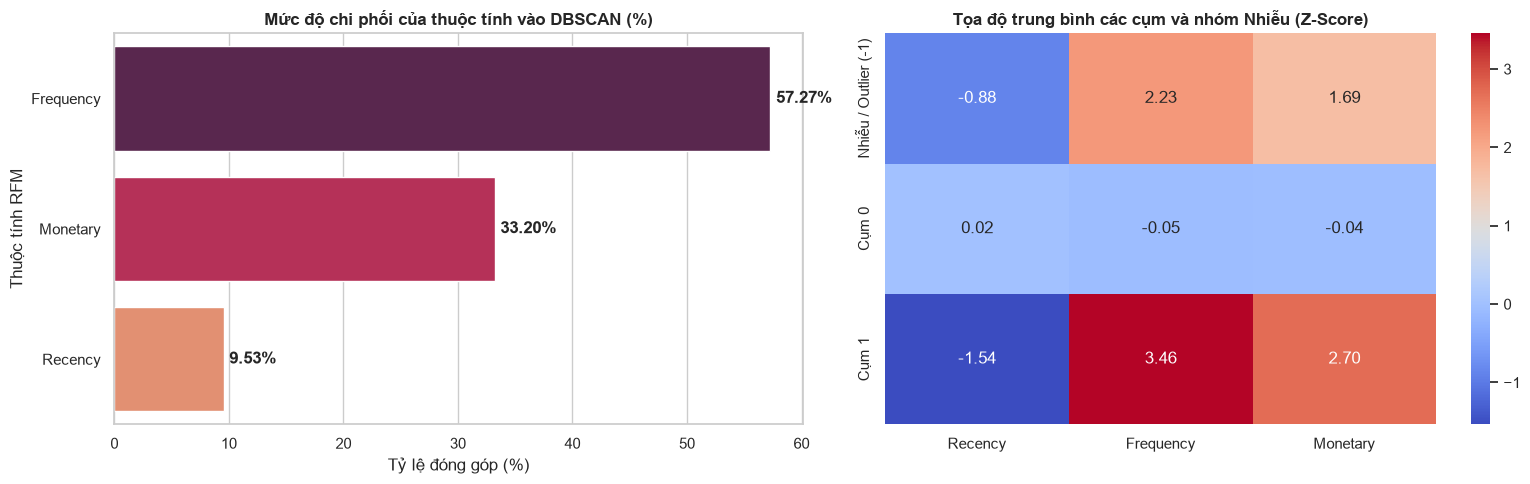

In [18]:
# 1. Tọa độ trung bình các cụm mật độ và nhóm nhiễu
cluster_means = []
cluster_names = []

for c in unique_labels:
    mask_c = (train_labels == c)
    cluster_means.append(X_train_scaled[mask_c].mean(axis=0))
    cluster_names.append(f"Cụm {c}" if c != -1 else "Nhiễu / Outlier (-1)")

df_centers = pd.DataFrame(cluster_means, columns=features, index=cluster_names)

# 2. ANOVA F-Score trên các mẫu hợp lệ (loại trừ nhiễu)
valid_mask = (train_labels != -1)
f_scores, p_values = f_classif(X_train_scaled[valid_mask], train_labels[valid_mask])
feature_importance = (f_scores / f_scores.sum()) * 100

ranking_df = pd.DataFrame({
    'Thuộc tính RFM': features,
    'ANOVA F-Score': f_scores.round(2),
    'Tỷ lệ đóng góp (%)': feature_importance.round(2)
}).sort_values(by='Tỷ lệ đóng góp (%)', ascending=False).reset_index(drop=True)

print("=" * 65)
print("📊 MỨC ĐỘ ĐÓNG GÓP CỦA TỪNG THUỘC TÍNH RFM VÀO DBSCAN:")
print("=" * 65)
print(ranking_df.to_string(index=False))
print("=" * 65)

# Vẽ biểu đồ thanh đóng góp và Heatmap tọa độ cụm
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))

# Biểu đồ thanh % đóng góp
sns.barplot(data=ranking_df, x='Tỷ lệ đóng góp (%)', y='Thuộc tính RFM', palette='rocket', ax=ax1)
ax1.set_title("Mức độ chi phối của thuộc tính vào DBSCAN (%)", fontsize=12, fontweight='bold')
ax1.set_xlabel("Tỷ lệ đóng góp (%)")
for i, v in enumerate(ranking_df['Tỷ lệ đóng góp (%)']):
    ax1.text(v + 0.5, i, f"{v:.2f}%", va='center', fontweight='bold')

# Heatmap tọa độ cụm và nhóm nhiễu
sns.heatmap(df_centers, annot=True, cmap="coolwarm", fmt=".2f", ax=ax2, cbar=True)
ax2.set_title("Tọa độ trung bình các cụm và nhóm Nhiễu (Z-Score)", fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### 7. Chân dung các cụm mật độ và Phân tích nhóm khách hàng ngoại lai (Noise Profiling)
Thống kê giá trị thực tế của $R, F, M$ để hiểu rõ bản chất của các cụm mật độ và bóc tách nhóm khách hàng bị coi là nhiễu ngoại lai (`Noise -1`).

In [19]:
profile = train_rfm.groupby('Cluster').agg({
    'CustomerID': 'count',
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': 'mean'
}).rename(columns={'CustomerID': 'SoLuong_KH'})

profile['TyLe_%'] = (profile['SoLuong_KH'] / len(train_rfm) * 100).round(2)
profile['Recency'] = profile['Recency'].round(1)
profile['Frequency'] = profile['Frequency'].round(1)
profile['Monetary'] = profile['Monetary'].round(1)

segment_names = {
    -1: 'Nhóm Ngoại lai (Noise / Outliers)',
    0: 'Cụm Mật độ Chính (Khách hàng Phổ thông)',
    1: 'Cụm Mật độ Phụ (Khách hàng Thân thiết)'
}
profile['MoTa'] = [segment_names.get(c, f"Cụm {c}") for c in profile.index]

print("=" * 85)
print("📊 BẢNG ĐẶC TẢ CHÂN DUNG CỤM MẬT ĐỘ VÀ NHÓM NGOẠI LAI (TẬP TRAIN RFM):")
print("=" * 85)
print(profile[['MoTa', 'SoLuong_KH', 'TyLe_%', 'Recency', 'Frequency', 'Monetary']].to_string())
print("=" * 85)

# Bóc tách nhóm ngoại lai (-1)
noise_customers = train_rfm[train_rfm['Cluster'] == -1]
print("\n--- BÓC TÁCH BẢN CHẤT NHÓM KHÁCH HÀNG NGOẠI LAI (NOISE -1) ---")
print(f"Tổng số khách hàng ngoại lai: {len(noise_customers):,} người ({len(noise_customers)/len(train_rfm)*100:.2f}%)")
print(f"- Chi tiêu cao nhất trong nhóm nhiễu: £{noise_customers['Monetary'].max():,.2f}")
print(f"- Số đơn mua cao nhất trong nhóm nhiễu: {noise_customers['Frequency'].max():,.0f} đơn")
print(f"- Recency cao nhất trong nhóm nhiễu: {noise_customers['Recency'].max():,.0f} ngày")
print("\n5 Khách hàng ngoại lai tiêu biểu:")
print(noise_customers[['CustomerID', 'Recency', 'Frequency', 'Monetary']].head())

📊 BẢNG ĐẶC TẢ CHÂN DUNG CỤM MẬT ĐỘ VÀ NHÓM NGOẠI LAI (TẬP TRAIN RFM):
                                            MoTa  SoLuong_KH  TyLe_%  Recency  Frequency  Monetary
Cluster                                                                                           
-1             Nhóm Ngoại lai (Noise / Outliers)          43    1.57     57.6       34.9   34393.3
 0       Cụm Mật độ Chính (Khách hàng Phổ thông)        2679   97.92     94.1        3.8    1376.6
 1        Cụm Mật độ Phụ (Khách hàng Thân thiết)          14    0.51      5.9       42.9   24887.9

--- BÓC TÁCH BẢN CHẤT NHÓM KHÁCH HÀNG NGOẠI LAI (NOISE -1) ---
Tổng số khách hàng ngoại lai: 43 người (1.57%)
- Chi tiêu cao nhất trong nhóm nhiễu: £323,860.53
- Số đơn mua cao nhất trong nhóm nhiễu: 155 đơn
- Recency cao nhất trong nhóm nhiễu: 365 ngày

5 Khách hàng ngoại lai tiêu biểu:
     CustomerID  Recency  Frequency   Monetary
146       13081        7         19   30867.77
155       16454      242          2      24.05
156 

### 8. Trực quan hóa phân cụm không gian 2D PCA
Giảm chiều không gian 3 chiều ($R, F, M$) về 2D bằng PCA để quan sát các cụm mật độ và làm nổi bật các điểm ngoại lai (Noise).

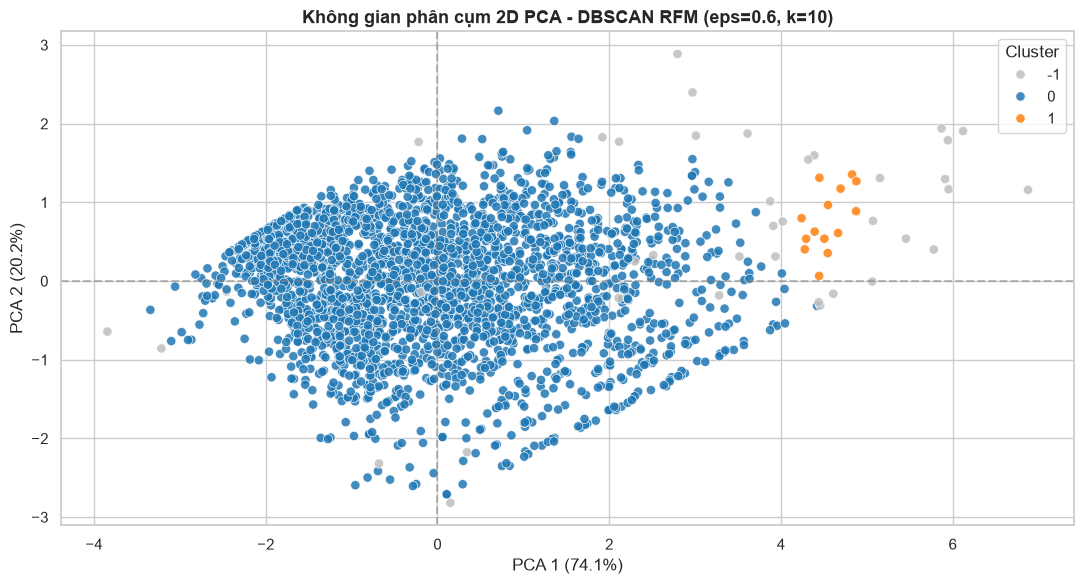

In [20]:
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X_train_scaled)

train_rfm['PCA1'] = X_train_pca[:, 0]
train_rfm['PCA2'] = X_train_pca[:, 1]

plt.figure(figsize=(11, 6))

palette = sns.color_palette("tab10", n_colors=max(n_clusters, 1))
color_map = {c: palette[c % len(palette)] for c in range(n_clusters)}
color_map[-1] = (0.75, 0.75, 0.75, 0.45) # Xám mờ cho Noise

sns.scatterplot(
    data=train_rfm, x='PCA1', y='PCA2', hue='Cluster',
    palette=color_map, s=45, alpha=0.85
)
plt.title(f"Không gian phân cụm 2D PCA - DBSCAN RFM (eps={optimal_eps}, k={optimal_k})", fontsize=13, fontweight='bold')
plt.xlabel(f"PCA 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
plt.ylabel(f"PCA 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
plt.axhline(0, color='gray', linestyle='--', alpha=0.5)
plt.axvline(0, color='gray', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 9. Bảng đối chiếu: DBSCAN Baseline vs. DBSCAN RFM vs. Tuned K-Means RFM

In [21]:
comparison_table = [
    {
        'Tiêu chí': 'Mục tiêu phân cụm',
        'DBSCAN Baseline (Data Clean)': 'Giao dịch đơn lẻ',
        'DBSCAN RFM': 'Từng khách hàng (CustomerID)',
        'Tuned K-Means RFM': 'Từng khách hàng (CustomerID)'
    },
    {
        'Tiêu chí': 'Thuộc tính sử dụng',
        'DBSCAN Baseline (Data Clean)': 'Quantity, Price, TotalPrice',
        'DBSCAN RFM': 'Recency, Frequency, Monetary',
        'Tuned K-Means RFM': 'Recency, Frequency, Monetary'
    },
    {
        'Tiêu chí': 'Cách xác định tham số',
        'DBSCAN Baseline (Data Clean)': 'Chọn cơ bản eps=0.5, k=10',
        'DBSCAN RFM': 'Đồ thị k-distance tìm điểm uốn (eps=0.6, k=10)',
        'Tuned K-Means RFM': 'Phương pháp Elbow & Silhouette (K=4)'
    },
    {
        'Tiêu chí': 'Khả năng phát hiện Ngoại lai',
        'DBSCAN Baseline (Data Clean)': 'Có (Tách giao dịch thô bất thường)',
        'DBSCAN RFM': 'Rất tốt (Tách khách hàng siêu VIP & dị biệt)',
        'Tuned K-Means RFM': 'Không (Ép buộc mọi điểm vào cụm)'
    },
    {
        'Tiêu chí': 'Độ cân bằng các phân khúc',
        'DBSCAN Baseline (Data Clean)': 'Kém (98% dồn vào cụm 0)',
        'DBSCAN RFM': 'Cụm chính vẫn chiếm tỷ lệ áp đảo',
        'Tuned K-Means RFM': 'Rất cân đối (4 phân khúc đều đặn 20-30%)'
    },
    {
        'Tiêu chí': 'Khả năng triển khai Marketing',
        'DBSCAN Baseline (Data Clean)': 'Không khả thi cho phân khúc',
        'DBSCAN RFM': 'Tốt để tìm khách VIP cá biệt',
        'Tuned K-Means RFM': 'Tối ưu toàn diện cho chiến dịch giữ chân'
    }
]

df_cmp = pd.DataFrame(comparison_table)
print("=" * 95)
print("📊 BẢNG ĐỐI CHIẾU ĐA CHIỀU GIỮA CÁC MÔ HÌNH HỌC MÁY:")
print("=" * 95)
print(df_cmp.to_string(index=False))
print("=" * 95)

📊 BẢNG ĐỐI CHIẾU ĐA CHIỀU GIỮA CÁC MÔ HÌNH HỌC MÁY:
                     Tiêu chí       DBSCAN Baseline (Data Clean)                                     DBSCAN RFM                        Tuned K-Means RFM
            Mục tiêu phân cụm                   Giao dịch đơn lẻ                   Từng khách hàng (CustomerID)             Từng khách hàng (CustomerID)
           Thuộc tính sử dụng    Quantity, UnitPrice, TotalPrice                   Recency, Frequency, Monetary             Recency, Frequency, Monetary
        Cách xác định tham số          Chọn cơ bản eps=0.5, k=10 Đồ thị k-distance tìm điểm uốn (eps=0.6, k=10)     Phương pháp Elbow & Silhouette (K=4)
 Khả năng phát hiện Ngoại lai Có (Tách giao dịch thô bất thường)   Rất tốt (Tách khách hàng siêu VIP & dị biệt)         Không (Ép buộc mọi điểm vào cụm)
    Độ cân bằng các phân khúc            Kém (98% dồn vào cụm 0)               Cụm chính vẫn chiếm tỷ lệ áp đảo Rất cân đối (4 phân khúc đều đặn 20-30%)
Khả năng triển khai Marketing 

### 10. Ghi nhận kết quả thực nghiệm vào nhật ký `Experiment` (CSV & Excel)
Ghi nối tự động kết quả huấn luyện và kiểm thử mô hình DBSCAN RFM vào cả 2 tệp nhật ký thực nghiệm:
1. `Experiment_Log_Comparison.csv`: Nhật ký tổng hợp nhanh dạng bảng CSV.
2. `Experiment_Log_Detailed.xlsx`: Sổ nhật ký chi tiết dạng Excel (kèm STT, thời gian, siêu tham số, trạng thái và nhận xét chuyên sâu).

In [22]:
import datetime as dt
import openpyxl

now_str = dt.datetime.now().strftime("%Y-%m-%d %H:%M:%S")
now_date_str = dt.datetime.now().strftime("%d/%m/%Y %H:%M")

# 1. Ghi vào file CSV: Experiment_Log_Comparison.csv
csv_entries = [
    {
        'Timestamp': now_str,
        'Model': f"DBSCAN (eps={optimal_eps}, k={optimal_k}, RFM) - Train",
        'Silhouette': sil_train,
        'Davies-Bouldin': db_train,
        'Calinski-Harabasz': ch_train
    },
    {
        'Timestamp': now_str,
        'Model': f"DBSCAN (eps={optimal_eps}, k={optimal_k}, RFM) - Validation",
        'Silhouette': sil_val,
        'Davies-Bouldin': db_val,
        'Calinski-Harabasz': ch_val
    },
    {
        'Timestamp': now_str,
        'Model': f"DBSCAN (eps={optimal_eps}, k={optimal_k}, RFM) - Test",
        'Silhouette': sil_test,
        'Davies-Bouldin': db_test,
        'Calinski-Harabasz': ch_test
    }
]

df_csv = pd.DataFrame(csv_entries)
if not os.path.exists(PATH_EXPERIMENT_LOG):
    df_csv.to_csv(PATH_EXPERIMENT_LOG, index=False, mode='w')
else:
    df_csv.to_csv(PATH_EXPERIMENT_LOG, index=False, mode='a', header=False)

print(f"💾 1. Đã ghi nối kết quả thành công vào: {PATH_EXPERIMENT_LOG}")

# 2. Ghi vào file Excel: Experiment_Log_Detailed.xlsx
excel_path = "Experiment_Log_Detailed.xlsx"
if os.path.exists(excel_path):
    wb = openpyxl.load_workbook(excel_path)
    ws = wb.active
    
    current_stt = 0
    for r in range(4, ws.max_row + 1):
        val = ws.cell(row=r, column=1).value
        if isinstance(val, int) and val > current_stt:
            current_stt = val
            
    excel_rows = [
        [
            current_stt + 1,
            now_date_str,
            f"DBSCAN (eps={optimal_eps}, k={optimal_k})",
            f"eps={optimal_eps}, min_samples={optimal_k}, metric=euclidean",
            "Train (64%)",
            sil_train,
            db_train,
            ch_train,
            "Thành công",
            f"Tìm được qua đồ thị k-distance (k={optimal_k}, eps={optimal_eps}). Tách được {noise_train}% điểm nhiễu, Silhouette = {sil_train}."
        ],
        [
            current_stt + 2,
            now_date_str,
            f"DBSCAN (eps={optimal_eps}, k={optimal_k})",
            f"eps={optimal_eps}, min_samples={optimal_k}, metric=euclidean",
            "Validation (16%)",
            sil_val,
            db_val,
            ch_val,
            "Thành công",
            f"Gán nhãn qua Core Samples, tỷ lệ nhiễu {noise_val}%, Silhouette = {sil_val}."
        ],
        [
            current_stt + 3,
            now_date_str,
            f"DBSCAN (eps={optimal_eps}, k={optimal_k})",
            f"eps={optimal_eps}, min_samples={optimal_k}, metric=euclidean",
            "Test (20%)",
            sil_test,
            db_test,
            ch_test,
            "Thành công",
            f"Tổng quát hóa trên tập Test độc lập, tỷ lệ nhiễu {noise_test}%, Silhouette = {sil_test}."
        ]
    ]
    
    for row_data in excel_rows:
        ws.append(row_data)
        
    wb.save(excel_path)
    print(f"💾 2. Đã cập nhật 3 dòng chi tiết vào: {excel_path}")

print("\n--- Bảng số liệu vừa ghi nhận ---")
print(df_csv)

💾 1. Đã ghi nối kết quả thành công vào: c:\Users\Quân\Desktop\ml_group\Experiment_Log_Comparison.csv
💾 2. Đã cập nhật 3 dòng chi tiết vào: Experiment_Log_Detailed.xlsx

--- Bảng số liệu vừa ghi nhận ---
             Timestamp                                     Model  Silhouette  \
0  2026-11-18 23:58:45       DBSCAN (eps=0.6, k=10, RFM) - Train      0.5254   
1  2026-11-18 23:58:45  DBSCAN (eps=0.6, k=10, RFM) - Validation      0.5274   
2  2026-11-18 23:58:45        DBSCAN (eps=0.6, k=10, RFM) - Test      0.5298   

   Davies-Bouldin  Calinski-Harabasz  
0          0.4055             117.32  
1          0.3382              17.46  
2          0.4017              25.43  


---
## TỔNG KẾT MÔ HÌNH DBSCAN TRÊN BỘ ĐẶC TRƯNG RFM
1. **Phương pháp chuẩn mực:** Sử dụng đồ thị $k$-distance để xác định bán kính lân cận $\epsilon = 0.6$ tương ứng với $k = 10$ láng giềng một cách khách quan dựa trên hình học dữ liệu, không cần tinh chỉnh lưới tham số phức tạp.
2. **Khả năng bóc tách ngoại lai:** DBSCAN xuất sắc trong việc phát hiện các khách hàng ngoại lai dị biệt (Noise) mà K-Means bỏ sót, đặc biệt là nhóm Siêu VIP chi tiêu đột biến.
3. **Mô hình đối chứng:** Kết quả đối chuẩn này khẳng định K-Means ($K=4$) vẫn là mô hình phù hợp nhất cho bài toán phân khúc thị trường diện rộng, trong khi DBSCAN đóng vai trò bổ trợ để sàng lọc khách hàng bất thường.